# AML model comparison

Compare logistic regression, Random Forest, and Histogram Gradient Boosting on the same split and transaction features. `laundering_typology` is kept for evaluation only.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 2137
DATA_PATH = Path("dataset.csv")

## Load and prepare features

In [2]:
usecols = [
    "type", "category", "orig", "dest", "old_balance", "new_balance",
    "is_fraud", "laundering_typology", "payment_method", "location.city",
    "device_info.type", "device_info.os", "datetime",
]
dtypes = {
    "type": "category", "category": "category",
    "orig": "category", "dest": "category",
    "old_balance": "float32", "new_balance": "float32",
    "is_fraud": "int8", "laundering_typology": "category",
    "payment_method": "category", "location.city": "category",
    "device_info.type": "category", "device_info.os": "category",
}

df = pd.read_csv(DATA_PATH, usecols=usecols, dtype=dtypes, parse_dates=["datetime"])
df = df.sort_values("datetime", kind="stable").reset_index(drop=True)
df["amount"] = (df["old_balance"] - df["new_balance"]).clip(lower=0).astype("float32")
df["log_amount"] = np.log1p(df["amount"]).astype("float32")
df["log_old_balance"] = np.log1p(df["old_balance"].clip(lower=0)).astype("float32")
df["balance_fraction"] = (df["amount"] / df["old_balance"].clip(lower=1)).clip(0, 1).astype("float32")

hour = df["datetime"].dt.hour + df["datetime"].dt.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * hour / 24).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * hour / 24).astype("float32")
df["is_weekend"] = (df["datetime"].dt.dayofweek >= 5).astype("float32")
df["destination_is_merchant"] = df["dest"].astype(str).str.startswith("M").astype("float32")
df["near_threshold"] = df["amount"].between(8_500, 10_000, inclusive="left").astype("float32")

orig_count = df.groupby("orig", observed=True).cumcount().astype("float32")
dest_count = df.groupby("dest", observed=True).cumcount().astype("float32")
pair_count = df.groupby(["orig", "dest"], observed=True).cumcount().astype("float32")
df["log_orig_prior_count"] = np.log1p(orig_count).astype("float32")
df["log_dest_prior_count"] = np.log1p(dest_count).astype("float32")
df["log_pair_prior_count"] = np.log1p(pair_count).astype("float32")

previous_time = df.groupby("orig", observed=True)["datetime"].shift()
hours_since_previous = ((df["datetime"] - previous_time).dt.total_seconds() / 3600).clip(lower=0)
df["log_hours_since_orig_tx"] = np.log1p(hours_since_previous).astype("float32")
prior_sum = df.groupby("orig", observed=True)["amount"].cumsum() - df["amount"]
prior_mean = prior_sum / orig_count.replace(0, np.nan)
amount_ratio = (df["amount"] / prior_mean.clip(lower=1)).clip(upper=100)
df["log_amount_vs_orig_mean"] = np.log1p(amount_ratio).astype("float32")

numeric_features = [
    "log_amount", "log_old_balance", "balance_fraction", "hour_sin", "hour_cos",
    "is_weekend", "destination_is_merchant", "near_threshold",
    "log_orig_prior_count", "log_dest_prior_count", "log_pair_prior_count",
    "log_hours_since_orig_tx", "log_amount_vs_orig_mean",
]
categorical_features = [
    "type", "category", "payment_method", "location.city",
    "device_info.type", "device_info.os",
]
feature_columns = numeric_features + categorical_features
X = df[feature_columns].copy()
for column in categorical_features:
    X[column] = X[column].astype(object)
y = df["is_fraud"].to_numpy(dtype=np.int8)

## Split by time

In [3]:
n_rows = len(df)
train_end = int(0.60 * n_rows)
validation_end = int(0.80 * n_rows)

X_train, y_train = X.iloc[:train_end], y[:train_end]
X_validation, y_validation = X.iloc[train_end:validation_end], y[train_end:validation_end]
X_test, y_test = X.iloc[validation_end:], y[validation_end:]
typology_test = df["laundering_typology"].iloc[validation_end:].astype(str).to_numpy()

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_validation), len(y_test)],
    "positives": [int(y_train.sum()), int(y_validation.sum()), int(y_test.sum())],
    "positive_rate": [y_train.mean(), y_validation.mean(), y_test.mean()],
    "start": [df["datetime"].iloc[0], df["datetime"].iloc[train_end], df["datetime"].iloc[validation_end]],
    "end": [df["datetime"].iloc[train_end - 1], df["datetime"].iloc[validation_end - 1], df["datetime"].iloc[-1]],
}, index=["train", "validation", "test"])
display(split_summary)

,rows,positives,positive_rate,start,end
train,654103,1071,0.001637,2025-02-04 11:15:40,2025-05-23 04:00:16
validation,218034,372,0.001706,2025-05-23 04:00:23,2025-06-27 22:40:49
test,218035,302,0.001385,2025-06-27 22:41:05,2025-08-18 19:15:03


## Fit the models

In [4]:
def make_preprocessor(scale_numeric):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)),
    ])
    return ColumnTransformer(
        [("numeric", numeric_pipe, numeric_features),
         ("categorical", categorical_pipe, categorical_features)],
        sparse_threshold=0,
    )

model_specs = {
    "Logistic regression": (
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE), True
    ),
    "Random Forest": (
        RandomForestClassifier(
            n_estimators=120, max_depth=16, min_samples_leaf=2,
            max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE,
        ), False
    ),
    "HGBC": (
        HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=200, max_leaf_nodes=31,
            class_weight="balanced", random_state=RANDOM_STATE,
        ), False
    ),
}

def choose_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.argmax(f1))])

models = {}
validation_scores = {}
test_scores = {}
thresholds = {}
validation_rows = []

for name, (estimator, scale_numeric) in model_specs.items():
    model = Pipeline([
        ("preprocess", make_preprocessor(scale_numeric)),
        ("classifier", estimator),
    ])
    model.fit(X_train, y_train)
    models[name] = model
    validation_scores[name] = model.predict_proba(X_validation)[:, 1]
    test_scores[name] = model.predict_proba(X_test)[:, 1]
    thresholds[name] = choose_threshold(y_validation, validation_scores[name])
    validation_prediction = validation_scores[name] >= thresholds[name]
    validation_rows.append({
        "model": name,
        "average_precision": average_precision_score(y_validation, validation_scores[name]),
        "precision": precision_score(y_validation, validation_prediction, zero_division=0),
        "recall": recall_score(y_validation, validation_prediction, zero_division=0),
        "f1": f1_score(y_validation, validation_prediction, zero_division=0),
        "threshold": thresholds[name],
    })

validation_results = pd.DataFrame(validation_rows).set_index("model")
display(validation_results.sort_values("f1", ascending=False))

,average_precision,precision,recall,f1,threshold
model,,,,,
HGBC,0.919775,0.934718,0.846774,0.888575,0.987812
Random Forest,0.918562,0.960133,0.776882,0.858841,0.632713
Logistic regression,0.624576,0.716279,0.827957,0.768080,0.970911


## Precision–recall curves

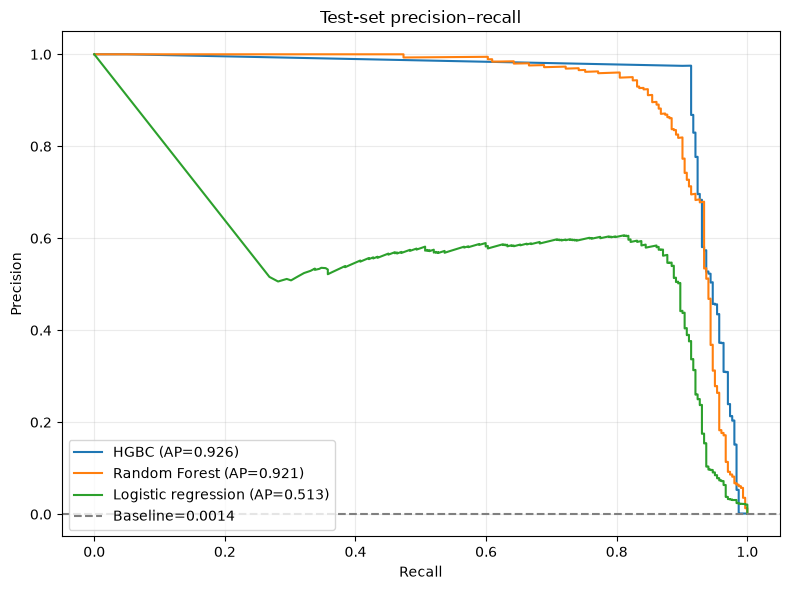

In [5]:
pr_order = sorted(
    models,
    key=lambda name: average_precision_score(y_test, test_scores[name]),
    reverse=True,
)
fig, ax = plt.subplots(figsize=(8, 6))
for name in pr_order:
    scores = test_scores[name]
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"Baseline={y_test.mean():.4f}")
ax.set(xlabel="Recall", ylabel="Precision", title="Test-set precision–recall")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Test metrics and confusion matrices

,average_precision,precision,recall,f1,alerts,validation_threshold
model,,,,,,
HGBC,0.925829,0.890323,0.913907,0.901961,310,0.987812
Random Forest,0.921160,0.962810,0.771523,0.856618,242,0.632713
Logistic regression,0.512695,0.577434,0.864238,0.692308,452,0.970911


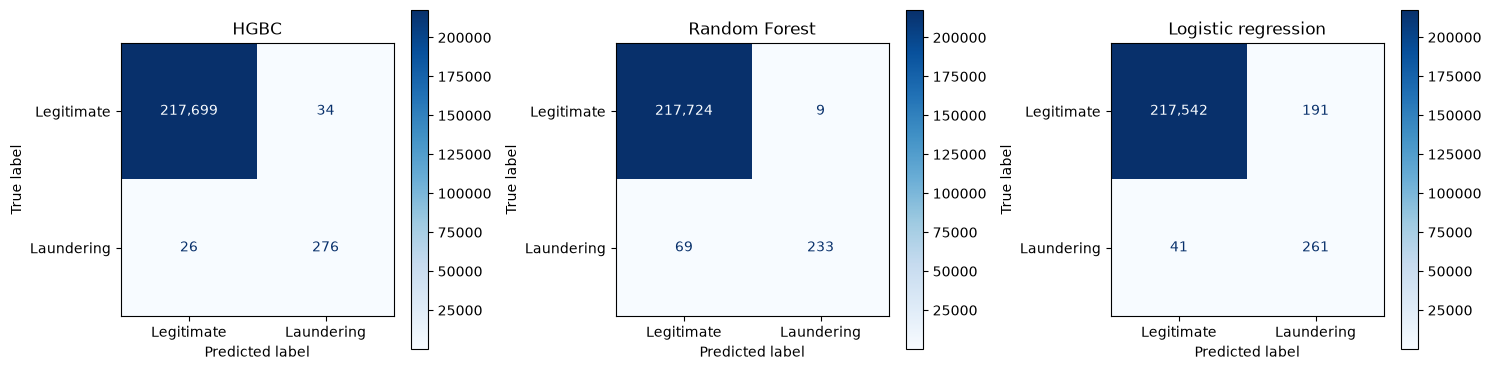

In [6]:
rows = []
test_predictions = {}
for name, scores in test_scores.items():
    prediction = scores >= thresholds[name]
    test_predictions[name] = prediction
    rows.append({
        "model": name,
        "average_precision": average_precision_score(y_test, scores),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "alerts": int(prediction.sum()),
        "validation_threshold": thresholds[name],
    })

results = pd.DataFrame(rows).set_index("model").sort_values("average_precision", ascending=False)
model_order = results.index.tolist()
display(results)

fig, axes = plt.subplots(1, len(model_order), figsize=(15, 4))
for ax, name in zip(axes, model_order):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[name], labels=[0, 1],
        display_labels=["Legitimate", "Laundering"],
        values_format=",d", cmap="Blues", ax=ax,
    )
    ax.set_title(name)
fig.tight_layout()
plt.show()

## Feature importance

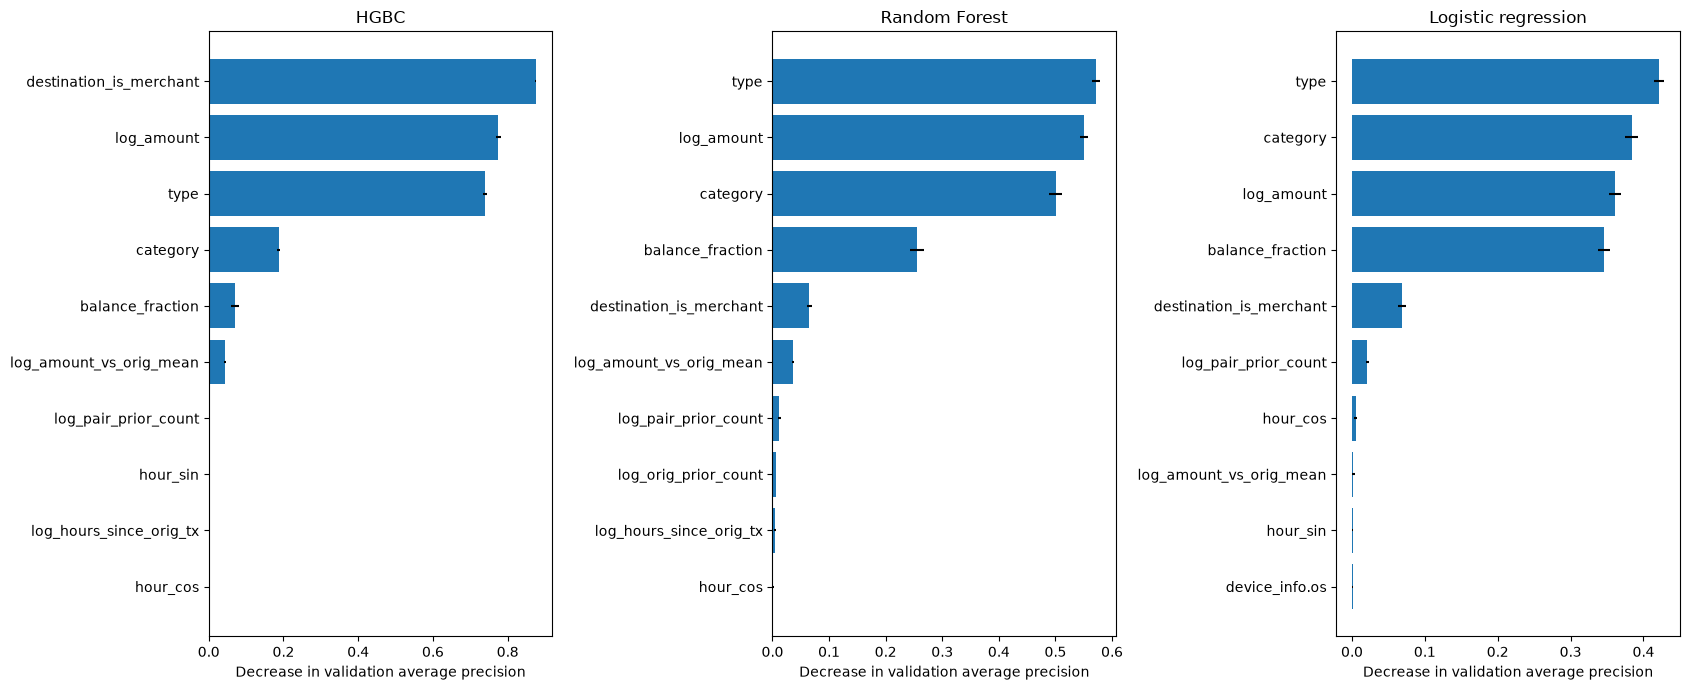

In [7]:
importance_rows = []
for name in model_order:
    result = permutation_importance(
        models[name], X_validation, y_validation,
        scoring="average_precision", n_repeats=3,
        random_state=RANDOM_STATE, n_jobs=1,
    )
    importance_rows.extend([
        {"model": name, "feature": feature, "importance": mean, "std": std}
        for feature, mean, std in zip(feature_columns, result.importances_mean, result.importances_std)
    ])

importance = pd.DataFrame(importance_rows)
fig, axes = plt.subplots(1, len(model_order), figsize=(17, 7))
for ax, name in zip(axes, model_order):
    top = (importance[importance["model"] == name]
           .nlargest(10, "importance")
           .sort_values("importance"))
    ax.barh(top["feature"], top["importance"], xerr=top["std"])
    ax.set_title(name)
    ax.set_xlabel("Decrease in validation average precision")
fig.tight_layout()
plt.show()

## Typology recall

The bars show the share detected for each laundering typology. Test support is included in each label because recall from a small group is less stable.

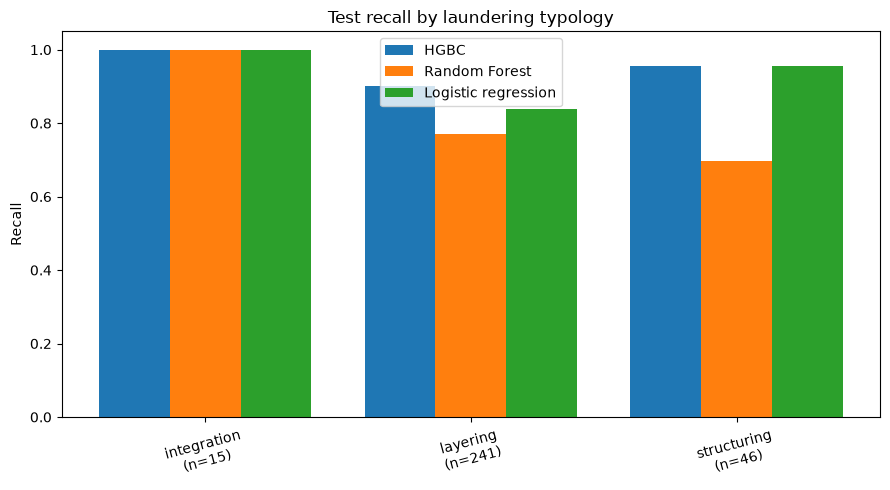

In [8]:
positive_typologies = sorted(set(typology_test) - {"normal"})
typology_support = {
    typology: int((typology_test == typology).sum())
    for typology in positive_typologies
}
typology_labels = [f"{t}\n(n={typology_support[t]})" for t in positive_typologies]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(positive_typologies))
width = 0.8 / len(model_order)
for index, name in enumerate(model_order):
    recalls = []
    for typology in positive_typologies:
        mask = typology_test == typology
        recalls.append(test_predictions[name][mask].mean() if mask.any() else np.nan)
    positions = x - 0.4 + width / 2 + index * width
    ax.bar(positions, recalls, width, label=name)
ax.set_xticks(x, typology_labels, rotation=15)
ax.set_ylim(0, 1.05)
ax.set(title="Test recall by laundering typology", ylabel="Recall")
ax.legend()
fig.tight_layout()
plt.show()